# Reading VTK meshes with pyramids-mesh

The **VTK** legacy format is the lingua franca of scientific visualization — written by [ParaView](https://www.paraview.org/), the VTK library itself, and conversion tools such as [meshio](https://github.com/nschloe/meshio). It stores an unstructured grid of points and cells in a plain ASCII (or binary) container.

A VTK file describes **geometry and topology only** — points live in a model-local Cartesian frame with no datum or projection. pyramids-mesh therefore reports `crs=None`: there is no georeferencing to speak of.

This tutorial uses `gh-935.vtk`, a tiny classic-v3.0 file: a unit square split into two triangles. We deliberately pick a **2D-surface** sample. The reader rejects a purely volumetric (tetrahedra) or line-only file with *“no 2D surface cell”*, because a `UgridDataset` models a 2D surface mesh, not a solid.

> Source: meshio test suite (`tests/meshes/vtk/`), MIT.

## Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [1]:
import numpy as np
import geopandas as gpd
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")  # resolved relative to THIS notebook
DATA
import matplotlib.pyplot as plt

## Quickstart: read the VTK file

`driver="vtk"` selects the VTK reader, which recognises both the legacy ASCII grammar and the newer VTK 5.1 `OFFSETS`/`CONNECTIVITY` layout.

The one rule that matters: **pass a `pathlib.Path`, never a `str`** — `read_file` keys its driver dispatch off the `Path` type. `UgridDataset.read_file(...)` returns a `UgridDataset`, the in-memory UGRID container every pyramids-mesh driver produces.

In [2]:
ds = UgridDataset.read_file(DATA / "vtk" / "gh-935.vtk", driver="vtk")
ds

UgridDataset(mesh='mesh2d', n_node=6, n_face=2, n_edge=0, variables=[])

In [3]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## What did we get?

A few scalar properties describe the dataset at a glance: node and face counts, the coordinate reference system, and the planar bounding box.

In [4]:
print("n_node :", ds.n_node)
print("n_face :", ds.n_face)
print("crs    :", ds.crs)
print("epsg   :", ds.epsg)
print("data   :", ds.data_variable_names)
print("bounds :", ds.bounds)

n_node : 6
n_face : 2
crs    : None
epsg   : None
data   : []
bounds : (0.0, 0.0, 1.0, 1.0)


`crs` and `epsg` are both `None` — exactly as expected for a visualization mesh in model-local coordinates. `data_variable_names` is **empty**: this file carries no point- or cell-data arrays, only the two triangles. The bounds `(0, 0, 1, 1)` confirm the unit square.

### Summary table

`ds.summary()` returns a pandas `DataFrame` with per-variable statistics (count / min / max / mean / std). With no data variables, the table here is empty — which is itself the finding: this is a pure-geometry file.

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,


## The mesh geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the **face-node connectivity**, an `(n_face, k)` integer table where `k` is the largest number of nodes any face has. Triangles fill 3 columns; quadrilaterals fill 4 (a shorter face pads the spare slot). `face_areas` and `face_centroids` are derived on demand.

In [6]:
mesh = ds.mesh
fnc = mesh.face_node_connectivity.data
areas = mesh.face_areas
cent = np.asarray(mesh.face_centroids)       # shape (2, n_face)
print("mesh type         :", type(mesh).__name__)
print("connectivity shape:", fnc.shape)
print("node_x range      :", float(mesh.node_x.min()), "->", float(mesh.node_x.max()))
print("node_y range      :", float(mesh.node_y.min()), "->", float(mesh.node_y.max()))
print("face_areas        :", float(areas.min()), "->", float(areas.max()))
print("centroids shape   :", cent.shape)

mesh type         : Mesh2d
connectivity shape: (2, 3)
node_x range      : 0.0 -> 1.0
node_y range      : 0.0 -> 1.0
face_areas        : 0.5 -> 0.5
centroids shape   : (2, 2)


The connectivity is `(2, 3)`: **two faces, three nodes each** — both cells are triangles. Six nodes span the unit square, and each triangle has area `0.5`, so the two together tile the whole square.

## Wireframe

`plot_outline()` draws the bare mesh edges — the quickest way to eyeball the topology and the element shapes before colouring anything.

Text(0.5, 1.0, 'VTK mesh outline')

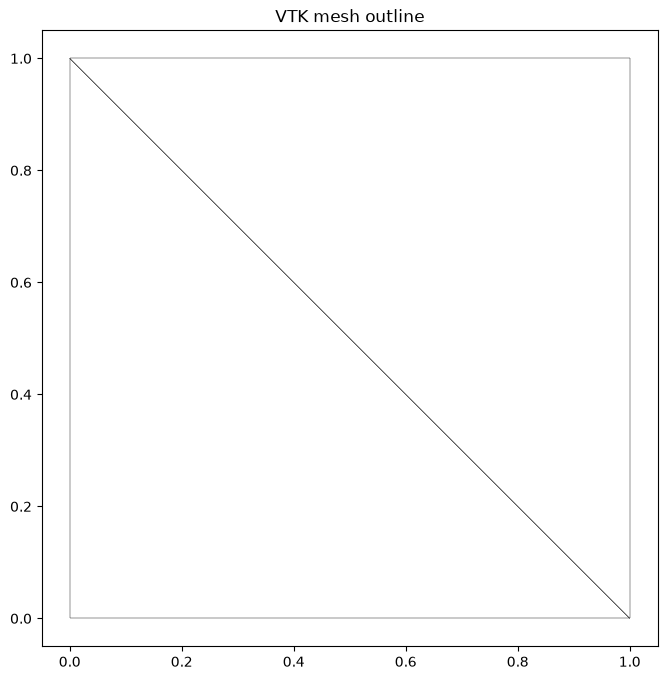

In [7]:
ds.plot_outline()
plt.title("VTK mesh outline")


## A derived field: cell area

These engineering files usually carry **no cell data** we can colour by — so we compute one ourselves. `with_variable` attaches `face_areas` as a face-located variable, giving a non-destructive copy of the dataset that `plot` can render as a filled colour map.

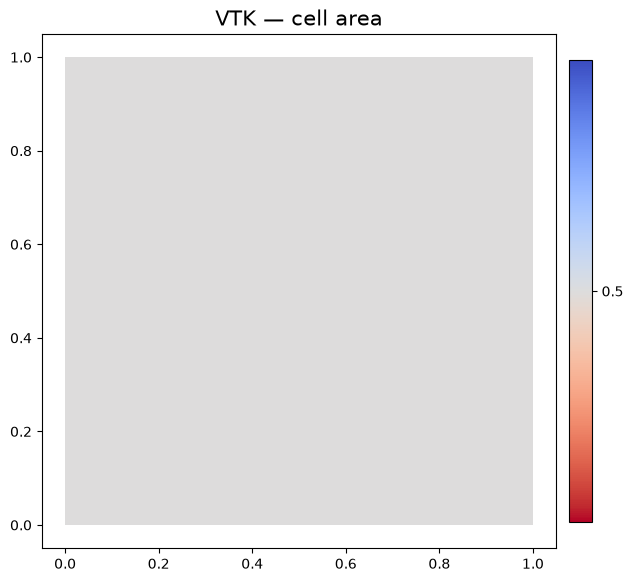

In [8]:
d2 = ds.with_variable("cell_area", ds.mesh.face_areas, location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="VTK — cell area")


Both triangles share the same `0.5` area, so the colour map is a single flat tone — the honest picture of a two-cell mesh.

## Treating the mesh as GIS

Because a `UgridDataset` is just nodes and polygonal faces, pyramids exposes the usual vector-GIS toolbox on it. First, every face as a GeoPandas polygon:

In [9]:
gdf = ds.to_geodataframe()
print(type(gdf).__name__, gdf.shape)
gdf.head()

GeoDataFrame (2, 1)


,geometry
0,"POLYGON ((0 1, 0 0, 1 0, 0 1))"
1,"POLYGON ((0 1, 1 0, 1 1, 0 1))"


Being a real `GeoDataFrame`, it plots with GeoPandas directly — a filled view of every element footprint:

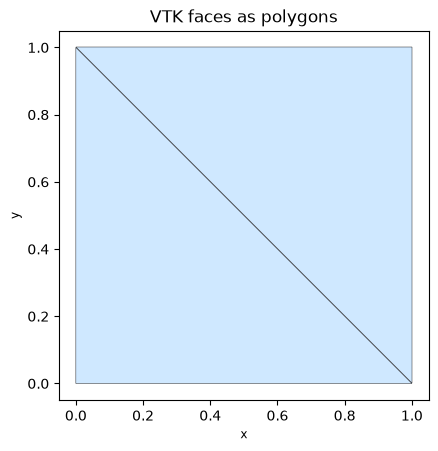

In [10]:
gdf.plot(edgecolor="black", linewidth=0.3, facecolor="#cfe8ff")
plt.title("VTK faces as polygons"); plt.gca().set_aspect("equal")


### The outer boundary

`bounding_polygon()` dissolves the faces into the single polygon that bounds the mesh — for this square, the unit square itself.

geometry type: Polygon


Text(0.5, 1.0, 'bounding polygon')

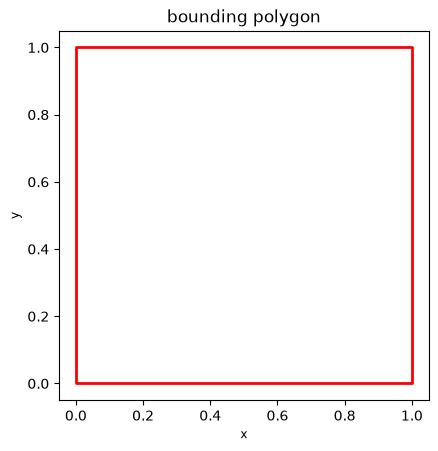

In [11]:
poly = ds.bounding_polygon()
print("geometry type:", poly.geom_type)
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="red", linewidth=2)
plt.gca().set_aspect("equal"); plt.title("bounding polygon")

### Cropping to a bounding box

`crop(bbox=...)` returns a new `UgridDataset` with only the faces inside the box — handy for zooming into a region of a large mesh. We crop to the left half of the extent.

faces before / after: 2 -> 1


Text(0.5, 1.0, 'cropped to the left half')

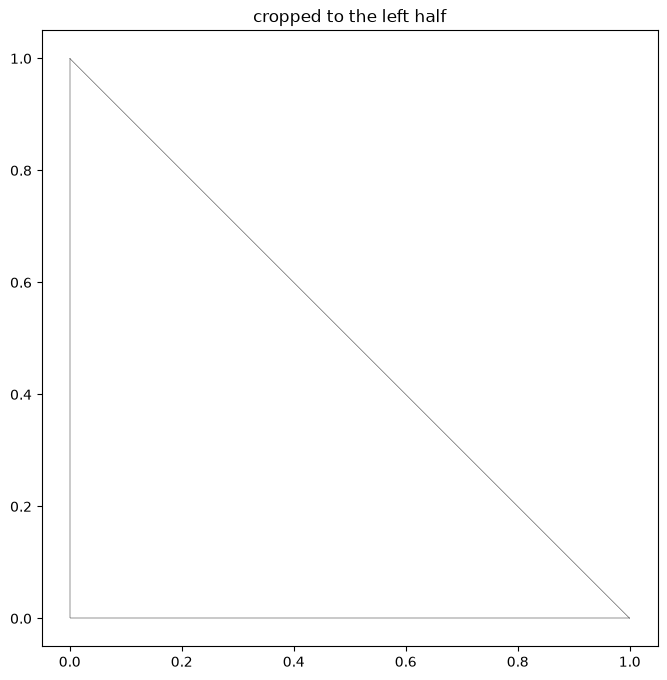

In [12]:
xmin, ymin, xmax, ymax = ds.bounds
half = ds.crop(bbox=(xmin, ymin, (xmin + xmax) / 2, ymax))
print("faces before / after:", ds.n_face, "->", half.n_face)
half.plot_outline(); plt.title("cropped to the left half")

### The face-adjacency graph

`sparse_adjacency()` gives the face-to-face adjacency as a SciPy sparse matrix, and `connected_components()` labels which faces are reachable from which. `plt.spy` shows the sparsity pattern — the fingerprint of how the faces are wired together.

adjacency: (2, 2) nnz = 0
connected components: 2


Text(0.5, 1.0, 'face adjacency')

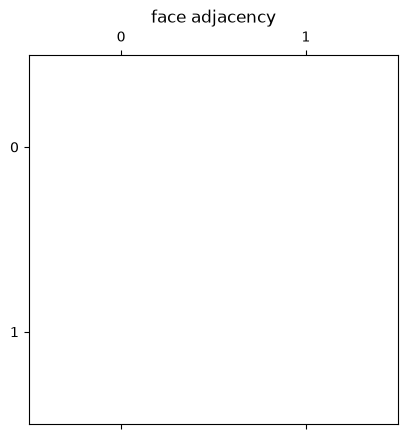

In [13]:
adj = ds.sparse_adjacency()
comp = ds.connected_components()
print("adjacency:", adj.shape, "nnz =", adj.nnz)
print("connected components:", np.unique(comp).size)
plt.spy(adj, markersize=0.6); plt.title("face adjacency")

The two triangles share one edge, so the mesh is a **single connected component** and the adjacency matrix has a lone off-diagonal pair — the simplest possible graph.

### A triangle-only operation: circumcenters

Because every face here is a triangle, `circumcenters()` is defined — it returns the centre of each triangle's circumscribed circle (the basis of a Voronoi dual). We overlay circumcenters (red) on area-weighted centroids (blue).

Text(0.5, 1.0, 'centroids vs circumcenters')

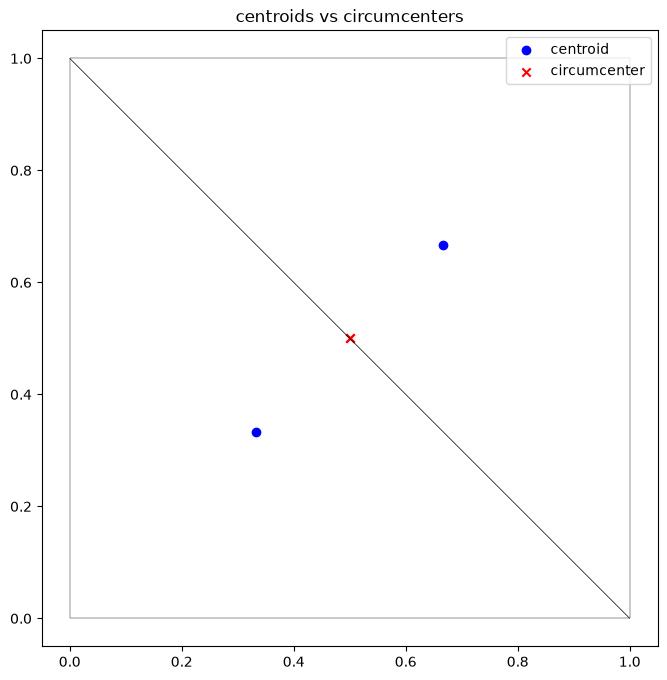

In [14]:
cc = ds.circumcenters()       # (2, n_face)
ct = np.asarray(ds.mesh.face_centroids)
ds.plot_outline()
plt.scatter(ct[0], ct[1], c="blue", label="centroid")
plt.scatter(cc[0], cc[1], c="red", marker="x", label="circumcenter")
plt.legend(); plt.title("centroids vs circumcenters")

### Converting out: xarray and other drivers

`to_xarray()` hands the whole UGRID dataset to xarray (dimensions named the CF-UGRID way), and `to_file(path, driver=...)` re-serialises it through any writer in the driver table — here a round-trip to the `2dm` format in a temp file.

In [15]:
import tempfile
xd = ds.to_xarray()
print("xarray dims:", dict(xd.sizes))
out = Path(tempfile.gettempdir()) / "vtk_roundtrip.2dm"
ds.to_file(out, driver="2dm")
print("wrote:", out.name, "| exists:", out.exists())

xarray dims: {'mesh2d_scalar': 1, 'mesh2d_nNodes': 6, 'mesh2d_nFaces': 2, 'mesh2d_nMaxFaceNodes': 3}
wrote: vtk_roundtrip.2dm | exists: True


### What we cannot do here: reprojection & regridding

`to_crs(epsg)` reprojects between coordinate systems — but this mesh has **`crs=None`** (model-local coordinates, no datum), so there is nothing to reproject from; we skip it. Likewise `rasterize_like(...)` and `regrid(...)` map a *data field* onto a raster or another mesh; with no meaningful field and no georeferencing on an engineering mesh they are out of scope. These belong on georeferenced hydrodynamic meshes, not FEM/CFD decks.

## Takeaway

- A VTK file is read with `UgridDataset.read_file(path, driver="vtk")` — **pass a `Path`** and point it at a **2D-surface** sample.
- It is geometry-only: `crs=None`, no data variables. We synthesised `cell_area` to get something to colour.
- Once loaded it behaves like any other mesh: wireframe, polygon export, cropping, the adjacency graph, and (because it is triangular) circumcenters.
- Reprojection/regridding do not apply — there is no CRS and no physical field.